# 1. Introduction

## Objective

The objective of this assignment is to develop and compare five supervised machine learning classification algorithms to predict whether an online shopping session will result in a purchase.

The Online Shoppers Purchasing Intention dataset is used to identify purchasing patterns based on visitor behavior, browsing activity, session characteristics, and traffic information.

The implemented classifiers are:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

The models are compared using Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC).

## Import the libraries

In [1]:
# LIBRARY IMPORTS & DISPLAY SETTINGS

# Import pandas for structured data manipulation and analysis
import pandas as pd

# Import numpy for scientific computing and array operations
import numpy as np

# Import matplotlib's pyplot for creating static, interactive, and animated visualizations
import matplotlib.pyplot as plt

# Import seaborn for high-level, aesthetically pleasing statistical graphics
import seaborn as sns

# Configure display options in pandas to prevent column truncation and manage output size
pd.set_option('display.max_columns', None)  # Show all columns without truncation
pd.set_option('display.max_rows', 100)     # Display up to 100 rows in outputs

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# MACHINE LEARNING & UTILITY IMPORTS

# Pipeline constructs sequentially applied lists of transforms and a final estimator
from sklearn.pipeline import Pipeline

# ColumnTransformer allows different columns or column subsets to be processed separately
from sklearn.compose import ColumnTransformer

# Preprocessors: StandardScaler scales features to unit variance, OneHotEncoder handles nominal categories
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import individual classifier implementations for our model suite
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

# Import utility modules for timing, serialization, and OS operations
import time    # For measuring model training latency
import joblib  # For saving and loading trained scikit-learn models
import os      # For directory management and path manipulation

In [3]:
# LIBRARIES FOR MODEL EVAL

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# 2. Dataset Loading

In [4]:
# Load dataset
df = pd.read_csv("online_shoppers_intention.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
# First five rows
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 12330
Number of columns: 18


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

**Observation:**

The dataset contains 12,330 rows and 18 features with a mix of numerical, categorical, and boolean types. Crucially, there are zero missing values across all columns, indicating a complete dataset ready for processing.

In [8]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [9]:
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Total missing values: 0


In [10]:
df.duplicated().sum()

np.int64(125)

**Observation:**

The dataset contains no missing or duplicate records.

# 3. Exploratory Data Analysis

In [11]:
print(df['Revenue'].value_counts())

print("\nPercentage distribution:")
print(df['Revenue'].value_counts(normalize=True) * 100)

Revenue
False    10422
True      1908
Name: count, dtype: int64

Percentage distribution:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


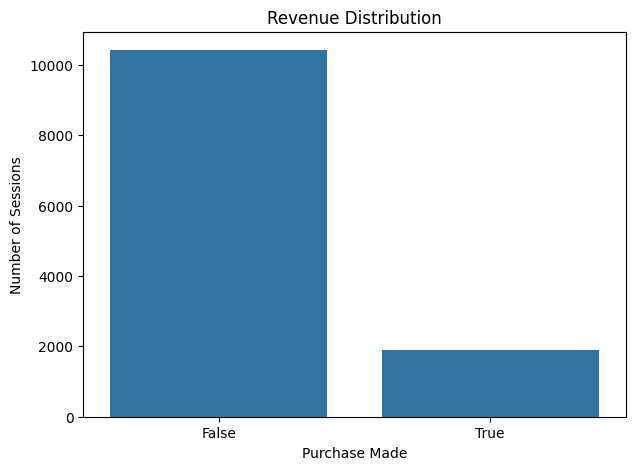

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Revenue')

plt.title('Revenue Distribution')
plt.xlabel('Purchase Made')
plt.ylabel('Number of Sessions')

plt.show()

**Observation:**

The target variable `Revenue` is highly imbalanced, with only ~15.5% of shopping sessions resulting in a purchase.

In [13]:
# Categorical features
categorical_features = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType',
    'Weekend'
]

# Numerical features
numerical_features = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Categorical features: 7
Numerical features: 10


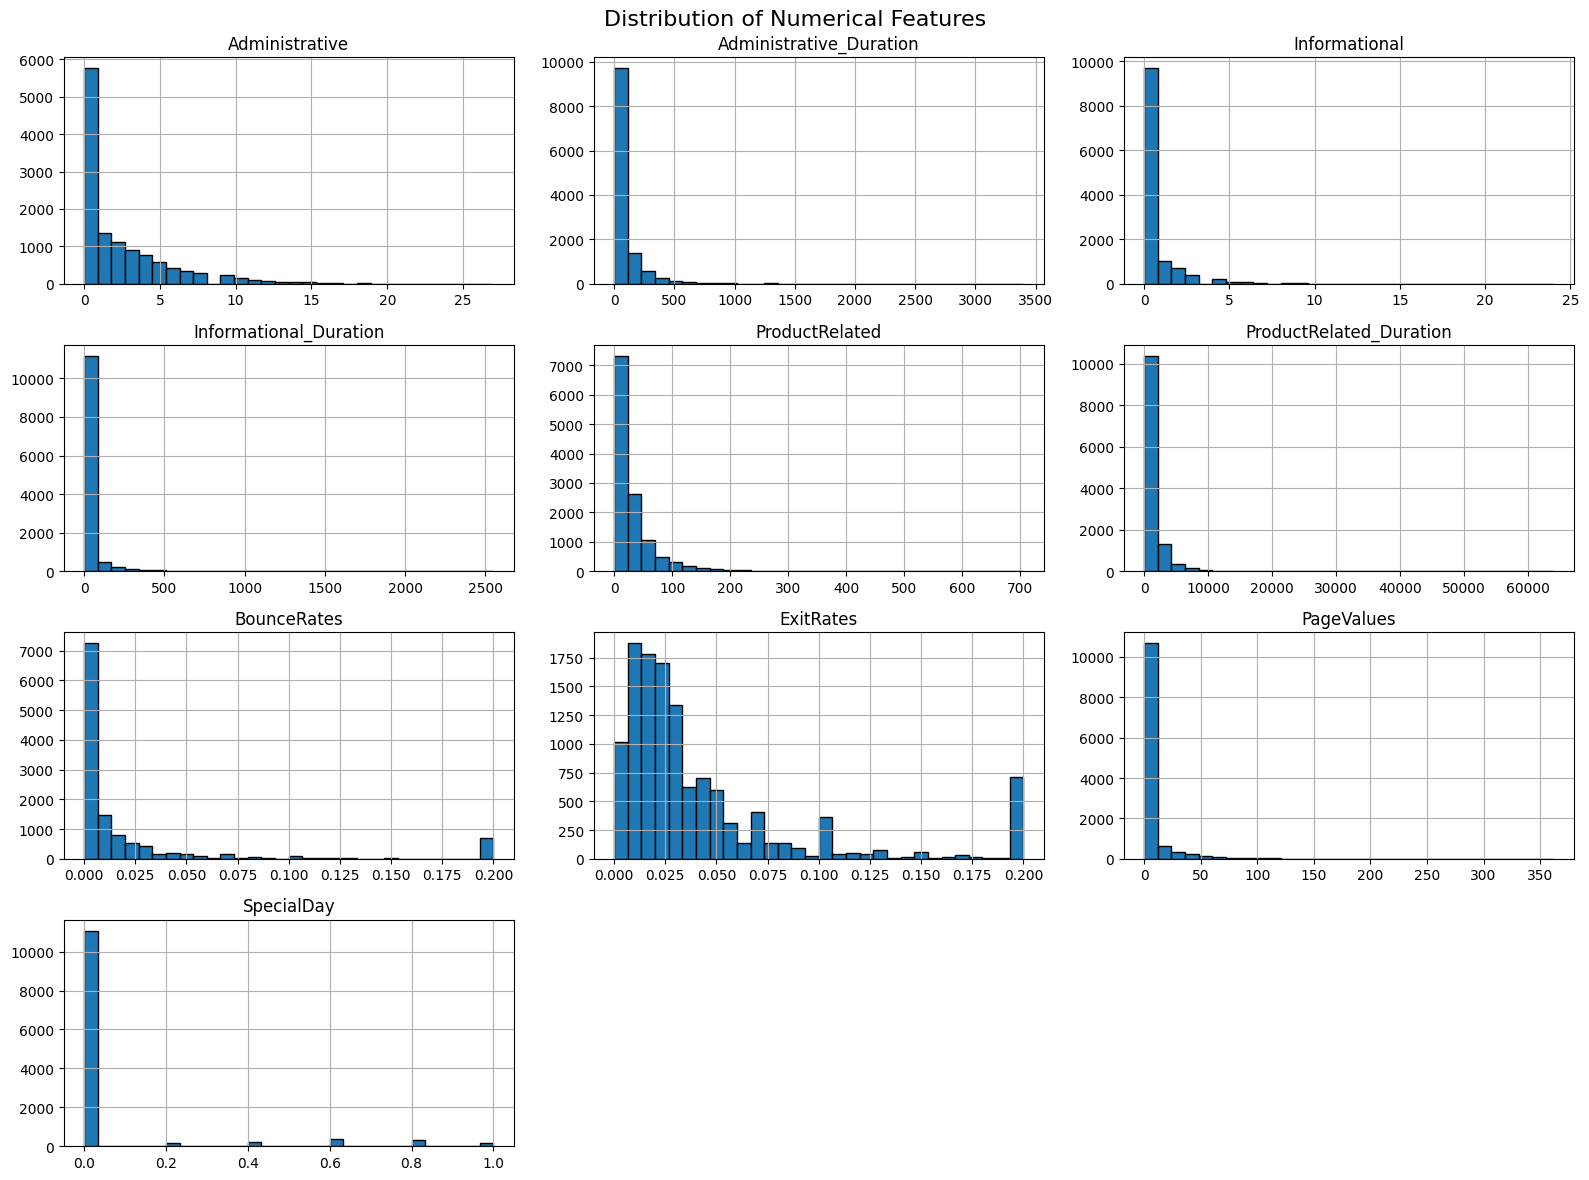

In [14]:
df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)

plt.tight_layout()
plt.show()

**Observation:**

Most numerical duration and page features are heavily right-skewed, showing that the majority of users spend very little time on informational or administrative pages.

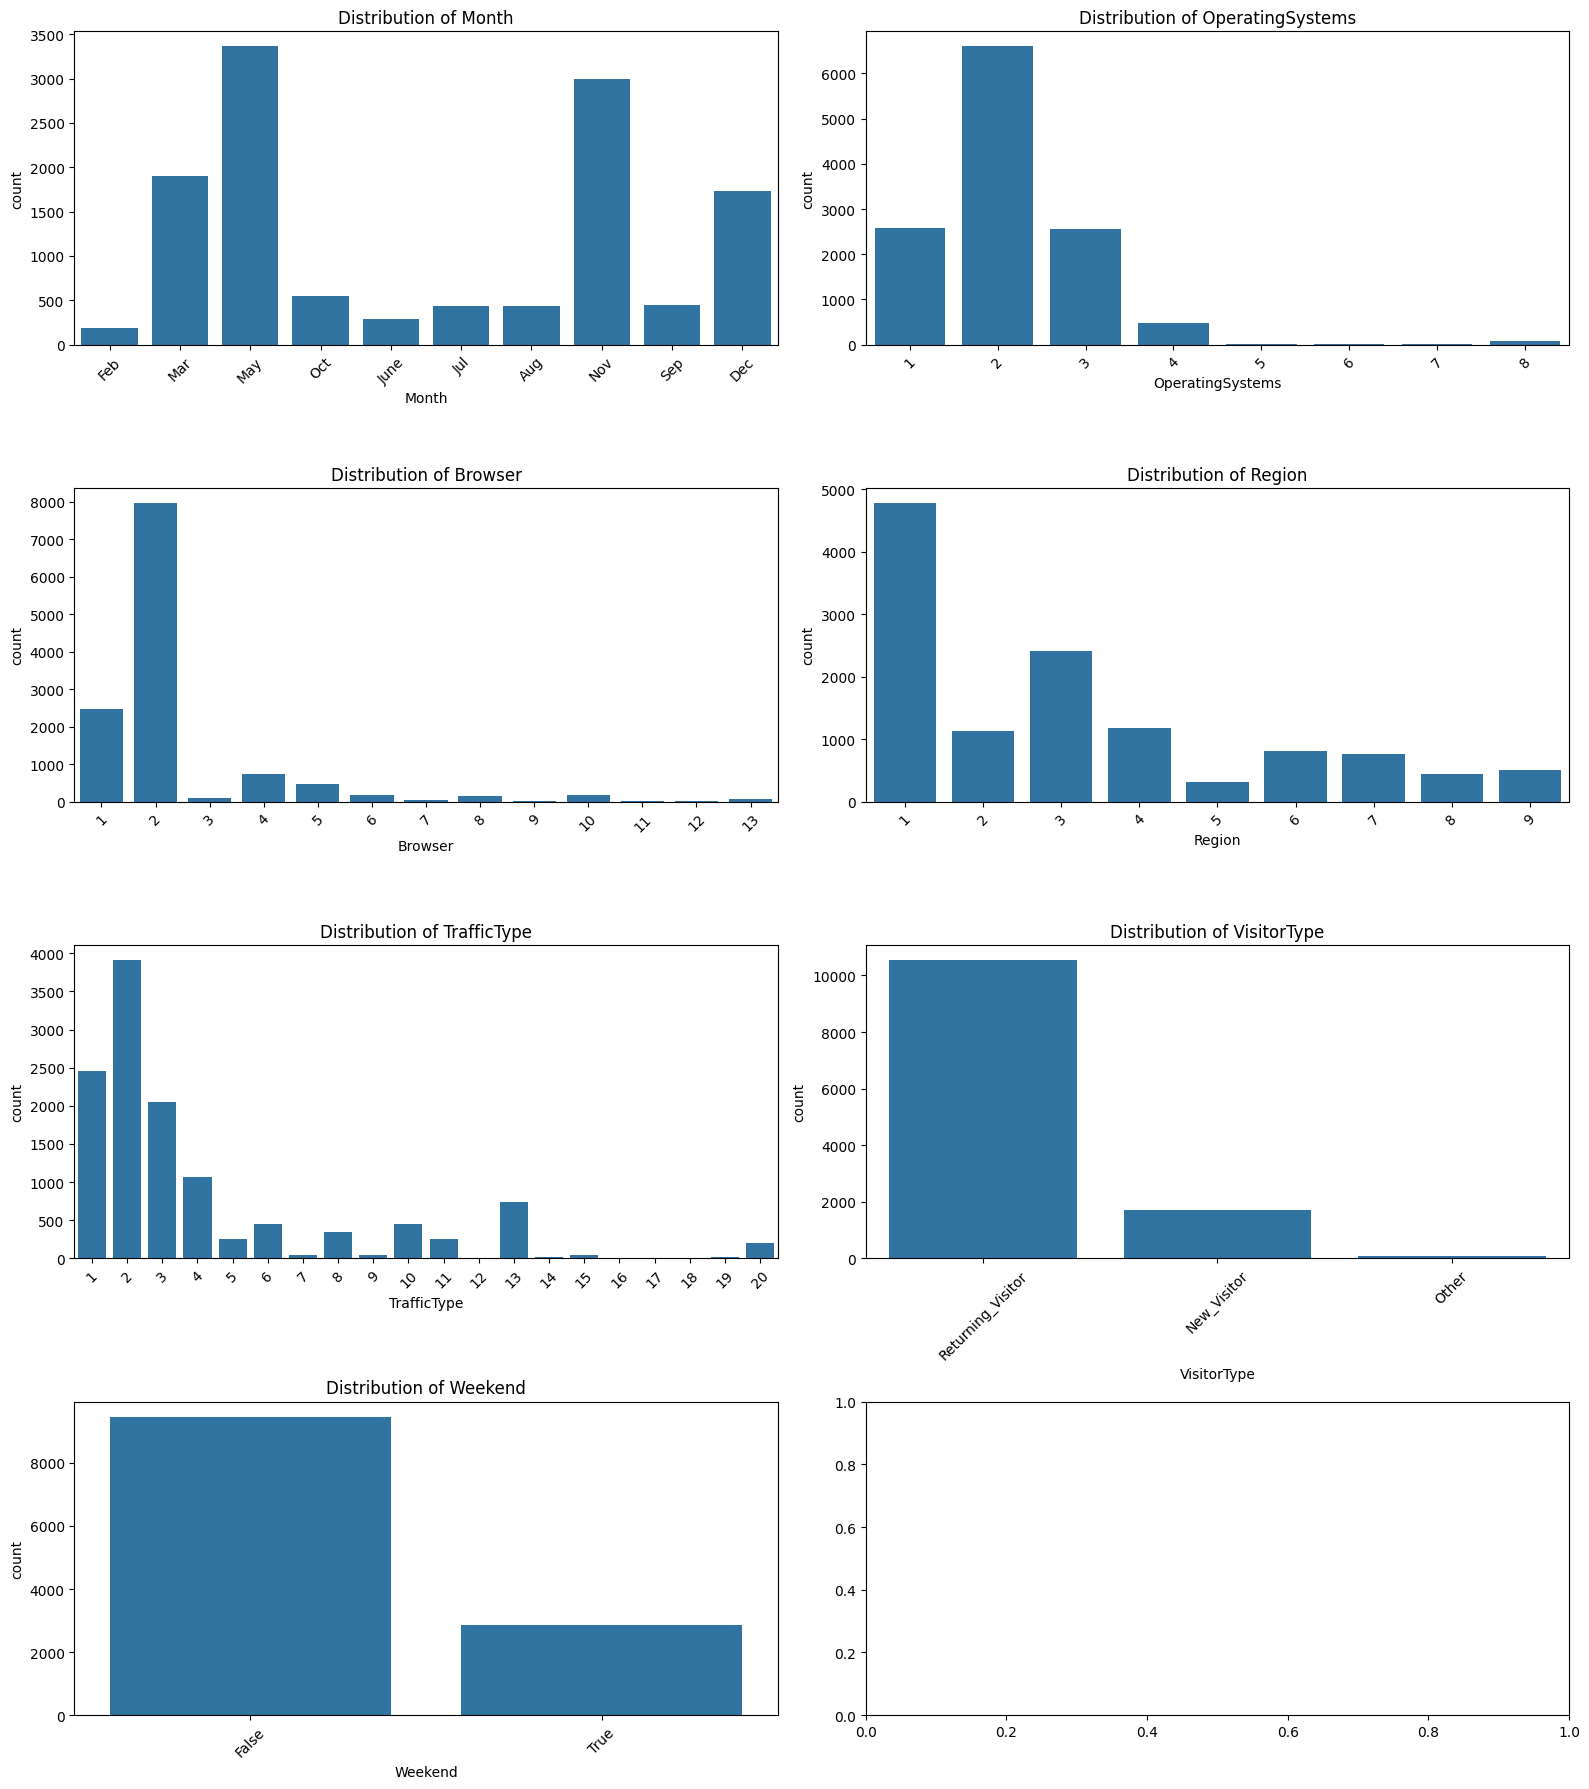

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    sns.countplot(
        data=df,
        x=feature,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {feature}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Observation:**

Most sessions occur in May and November, with returning visitors on common Operating Systems (2) and Browsers (2) dominating the traffic.

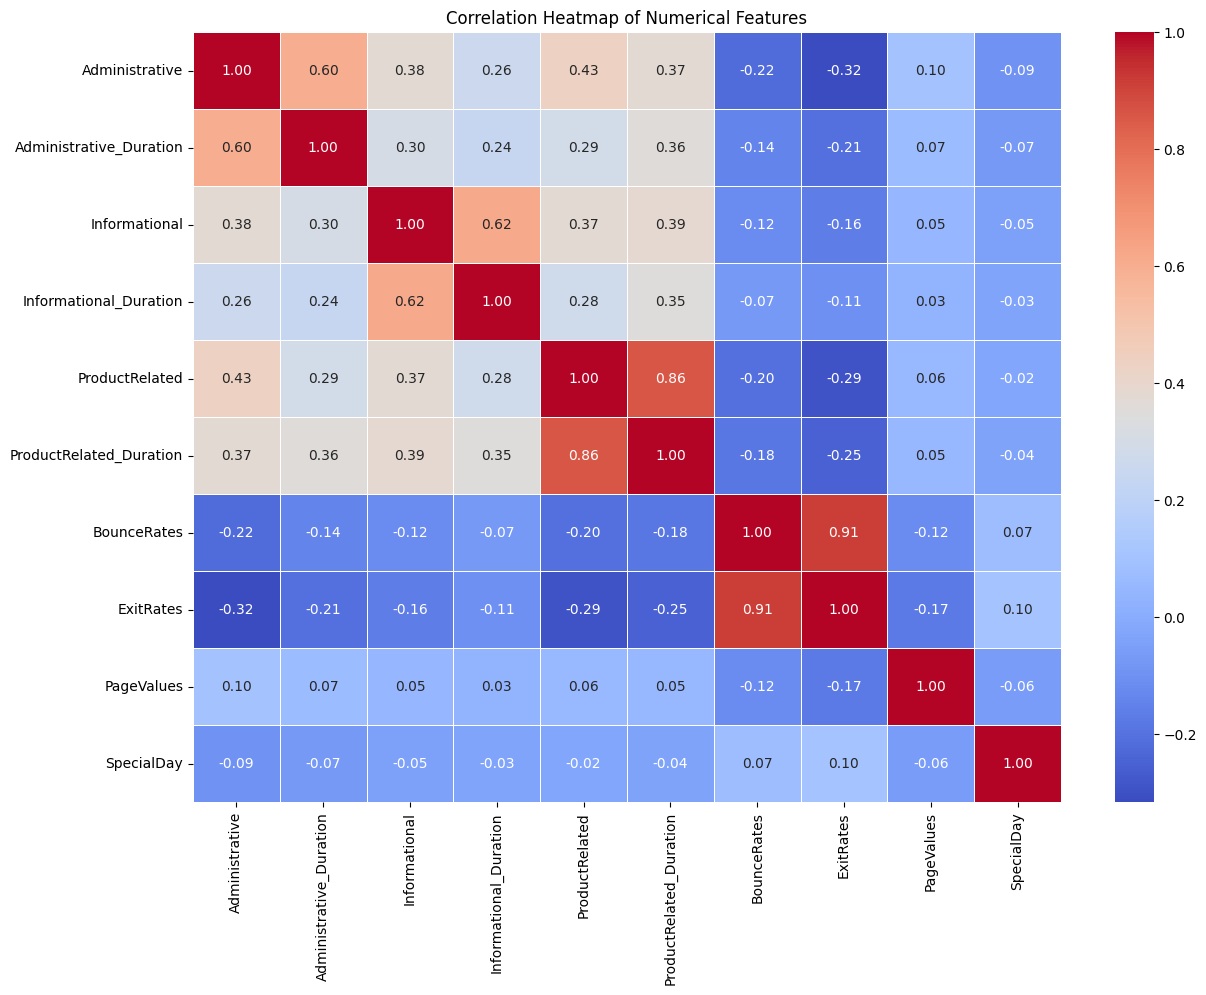

In [16]:
plt.figure(figsize=(14, 10))

correlation_matrix = df[numerical_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')

plt.show()

**Observation:**

Strong positive correlations exist between page counts and their respective durations (e.g., `ProductRelated` vs `ProductRelated_Duration` at 0.86), and a very high correlation (0.91) between `BounceRates` and `ExitRates`.

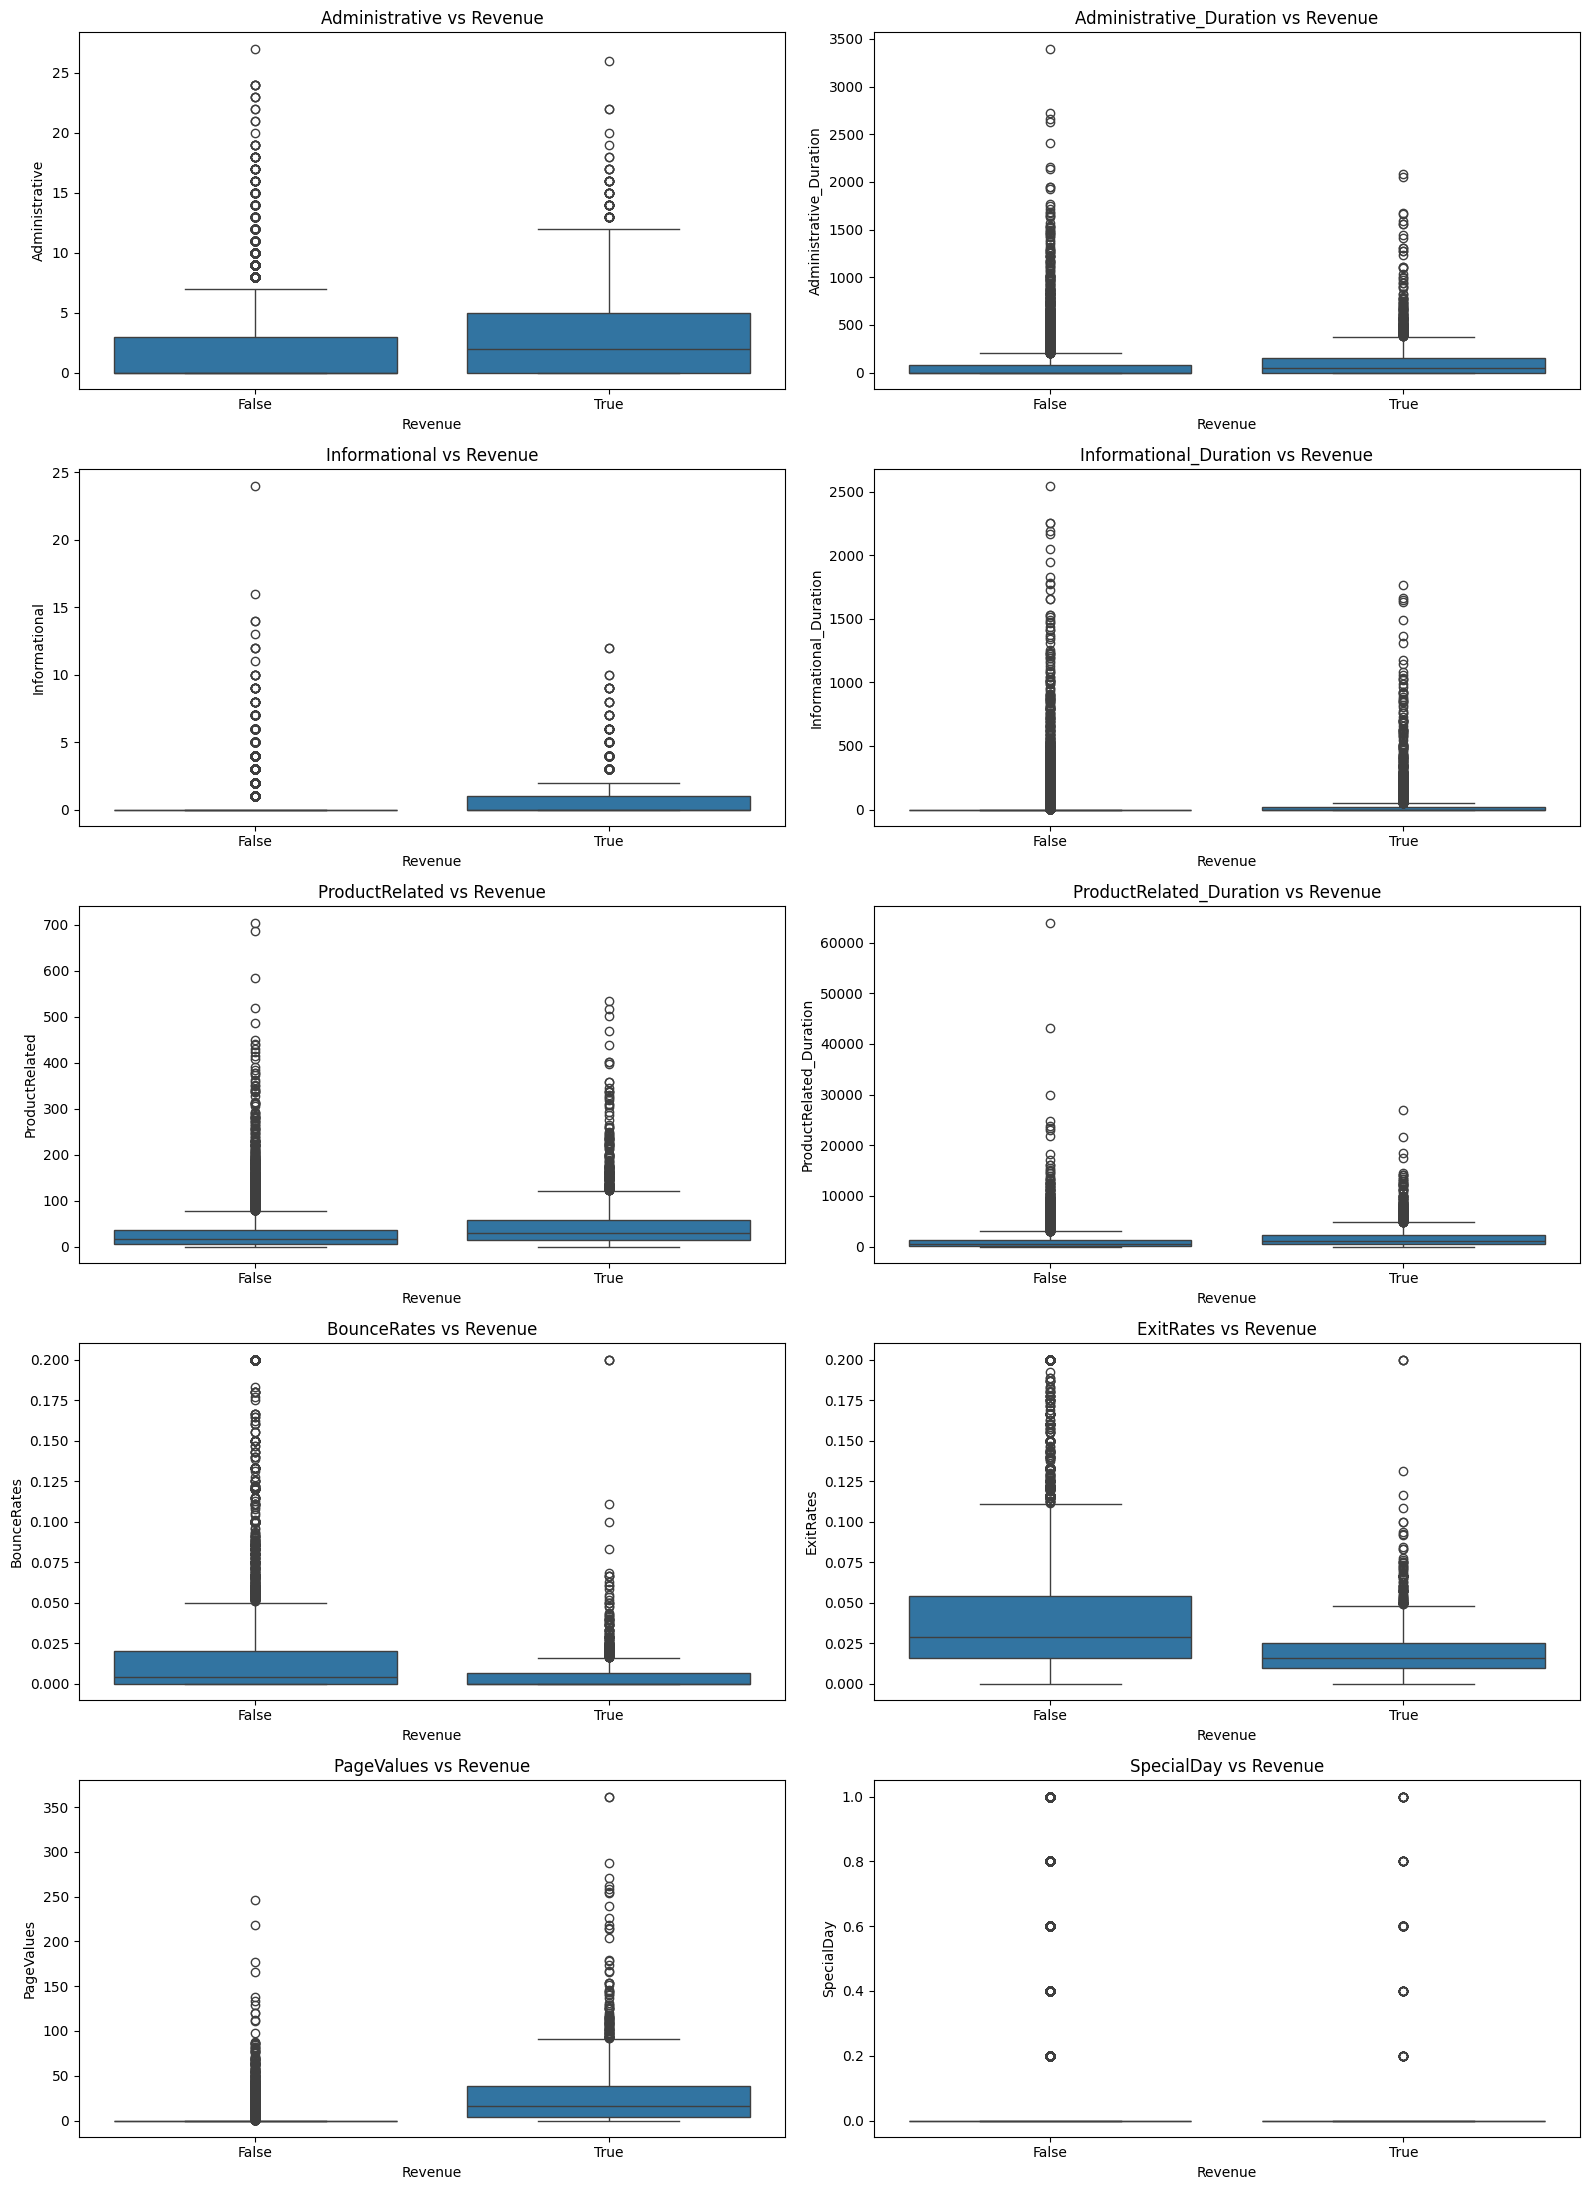

In [17]:
fig, axes = plt.subplots(5, 2, figsize=(16, 22))

axes = axes.flatten()

for i, feature in enumerate(numerical_features):

    sns.boxplot(
        data=df,
        x='Revenue',
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} vs Revenue')

plt.tight_layout()
plt.show()

**Observation:**

High `PageValues` strongly correlate with completed purchases, whereas sessions resulting in transactions consistently display much lower `BounceRates` and `ExitRates` compared to non-purchasing sessions.
```

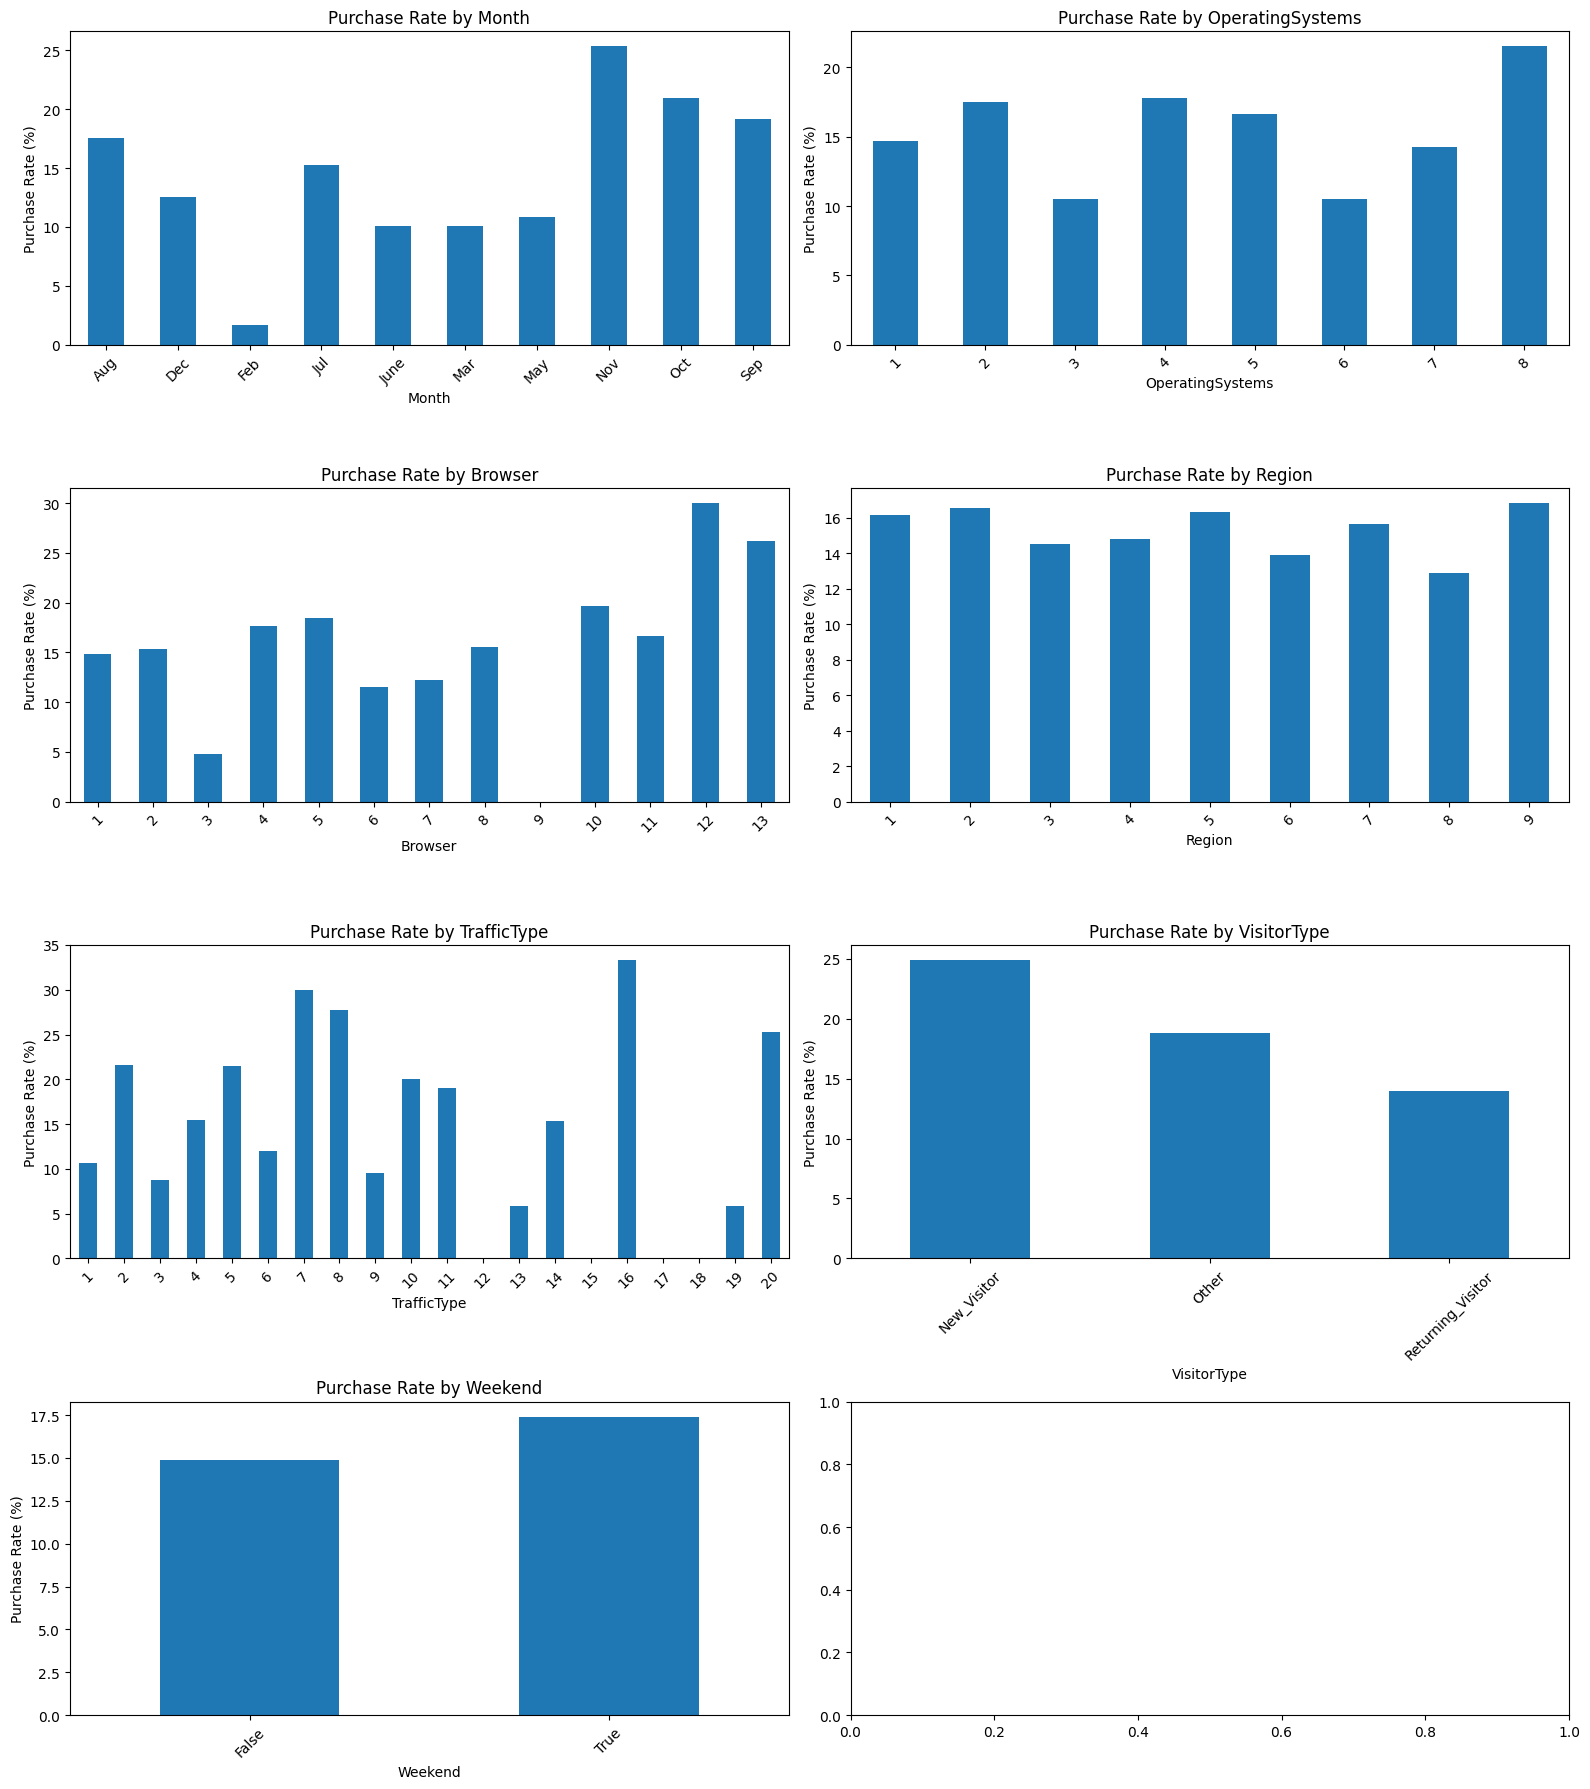

In [18]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    purchase_rate = df.groupby(feature, observed=True)['Revenue'].mean() * 100

    purchase_rate.plot(
        kind='bar',
        ax=axes[i]
    )

    axes[i].set_title(f'Purchase Rate by {feature}')
    axes[i].set_ylabel('Purchase Rate (%)')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Observation:**

November exhibits the highest purchase conversion rate (~25%), while new visitors and weekend sessions also show higher average purchase rates.

# 4. Data Preprocessing

In [19]:
# Separate input features and target variable

X = df.drop('Revenue', axis=1)
y = df['Revenue']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (12330, 17)
Target shape: (12330,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9864, 17)
Testing data: (2466, 17)


In [21]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Revenue
False    84.529603
True     15.470397
Name: proportion, dtype: float64

Testing target distribution:
Revenue
False    84.509327
True     15.490673
Name: proportion, dtype: float64


**Observation:**

Using a stratified split ensures that both the training (~15.47%) and testing (~15.49%) subsets maintain the exact same proportion of minority class transactions (`Revenue = True`), preventing evaluation bias.

In [22]:
# PREPROCESSING PIPELINE CONFIGURATION

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define the transformer for numerical features: Standardize to mean=0 and variance=1
numerical_transformer = StandardScaler()

# Define the transformer for categorical features: Convert categories into binary dummy variables
# handle_unknown='ignore' ensures robust evaluation if test data introduces unseen categories
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine both transformers into a single preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),  # Apply scaling to numerical features
        ('cat', categorical_transformer, categorical_features) # Apply OHE to categorical features
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [23]:
# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (9864, 75)
Processed testing shape: (2466, 75)


In [24]:
print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])

print("Training features:", X_train_processed.shape[1])
print("Testing features:", X_test_processed.shape[1])

print("Missing values in training:",
      np.isnan(X_train_processed.toarray()
      if hasattr(X_train_processed, 'toarray')
      else X_train_processed).sum())

Training samples: 9864
Testing samples: 2466
Training features: 75
Testing features: 75
Missing values in training: 0


In [25]:
# REUSABLE PRE-PROCESSOR PIPELINE

def create_preprocessor():
    """
    Factory function to instantiate and return a clean preprocessor instance.
    Prevents state leakage across different models by ensuring each model's
    pipeline receives a fresh, unfitted transformer.
    """
    # Scale numerical distributions to standard normal
    numerical_transformer = StandardScaler()

    # Encode categorical classes as multi-column binary flags
    categorical_transformer = OneHotEncoder(
        handle_unknown='ignore'
    )

    # Construct the transformer grid mapping specific columns to designated transformers
    # sparse_threshold=0 forces the preprocessor to output dense arrays directly
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_features),
            ('cat', categorical_transformer, categorical_features)
        ],
        sparse_threshold=0
    )

    return preprocessor

# 5. Model Development

In [26]:
# Define the 5 models

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Naive Bayes': GaussianNB(),

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    )
}

print("Five classification models defined successfully.")

Five classification models defined successfully.


In [27]:
# PIPELINE COMPOSITION

pipelines = {}

# Encapsulate each classifier alongside its data preprocessing steps inside a Pipeline
for model_name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', create_preprocessor()),  # Step 1: Preprocess raw input features
        ('classifier', model)                     # Step 2: Fit or evaluate the classifier
    ])

    # Store the configured pipeline in a dictionary indexed by model name
    pipelines[model_name] = pipeline

print("All five ML pipelines created successfully.")

All five ML pipelines created successfully.


# 6. Model Training

In [28]:
# PIPELINE TRAINING LOOP & LATENCY BENCHMARKING

training_times = {}

# Iterate through each defined machine learning pipeline to fit on the training subset
for model_name, pipeline in pipelines.items():

    print(f"\nTraining {model_name}...")

    # Capture initial timestamp
    start_time = time.time()

    # Fit pipeline: This automatically fits transformers on X_train and fits the model on transformed features
    pipeline.fit(X_train, y_train)

    # Capture final timestamp
    end_time = time.time()

    # Calculate total elapsed training time
    elapsed_time = end_time - start_time
    training_times[model_name] = elapsed_time

    print(f"{model_name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")


Training Logistic Regression...
Logistic Regression trained successfully.
Training time: 0.45 seconds

Training Decision Tree...
Decision Tree trained successfully.
Training time: 0.28 seconds

Training KNN...
KNN trained successfully.
Training time: 0.05 seconds

Training Naive Bayes...
Naive Bayes trained successfully.
Training time: 0.07 seconds

Training SVM...
SVM trained successfully.
Training time: 19.38 seconds


In [29]:
training_time_df = pd.DataFrame(
    list(training_times.items()),
    columns=['Model', 'Training Time (seconds)']
)

training_time_df.sort_values(
    by='Training Time (seconds)',
    ascending=True
)

,Model,Training Time (seconds)
2,KNN,0.046764
3,Naive Bayes,0.069106
1,Decision Tree,0.279496
0,Logistic Regression,0.450240
4,SVM,19.384108


**Observation:**

KNN and Naive Bayes are the fastest to train (<0.06s), while SVM is significantly slower, taking over 22 seconds.

In [30]:
for model_name, pipeline in pipelines.items():

    print(
        model_name,
        "->",
        "Trained" if hasattr(pipeline, 'classes_') else "Not trained"
    )

Logistic Regression -> Trained
Decision Tree -> Trained
KNN -> Trained
Naive Bayes -> Trained
SVM -> Trained


In [31]:
for model_name, pipeline in pipelines.items():

    print(
        model_name,
        ":",
        pipeline.named_steps['classifier'].classes_
    )

Logistic Regression : [False  True]
Decision Tree : [False  True]
KNN : [False  True]
Naive Bayes : [False  True]
SVM : [False  True]


In [32]:
# Create model directory
os.makedirs("model", exist_ok=True)

# Save each trained pipeline
for model_name, pipeline in pipelines.items():

    filename = model_name.lower().replace(" ", "_") + ".joblib"

    filepath = os.path.join("model", filename)

    joblib.dump(pipeline, filepath)

    print(f"Saved: {filepath}")

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/svm.joblib


# 7. Model Evaluation

In [33]:
# MODEL EVALUATION UTILITY FUNCTION

def evaluate_model(model, X_test, y_test):
    """
    Evaluates a trained classifier or pipeline on testing data and computes multiple metrics.

    Parameters:
    - model: Fitted estimator/pipeline
    - X_test: DataFrame/Array of input testing features
    - y_test: Series/Array of ground truth targets

    Returns:
    - metrics: Dict of computed metrics
    - y_pred: Predicted class labels
    - y_prob: Predicted probability estimates for positive class
    """
    # Predict class labels (True/False)
    y_pred = model.predict(X_test)

    # Predict probability of purchase (True class at index 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate key metrics including class-imbalance-robust scores (AUC, F1, MCC)
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),

        'AUC': roc_auc_score(y_test, y_prob),

        'Precision': precision_score(
            y_test, y_pred, pos_label=True, zero_division=0
        ),

        'Recall': recall_score(
            y_test, y_pred, pos_label=True, zero_division=0
        ),

        'F1 Score': f1_score(
            y_test, y_pred, pos_label=True, zero_division=0
        ),

        'MCC': matthews_corrcoef(y_test, y_pred) # Matthews Correlation Coefficient for overall balance
    }

    return metrics, y_pred, y_prob

In [34]:
results = []
predictions = {}
probabilities = {}

for model_name, pipeline in pipelines.items():

    print(f"\nEvaluating {model_name}...")

    metrics, y_pred, y_prob = evaluate_model(
        pipeline,
        X_test,
        y_test
    )

    results.append({
        'Model': model_name,
        **metrics
    })

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    print("Evaluation completed.")


Evaluating Logistic Regression...
Evaluation completed.

Evaluating Decision Tree...
Evaluation completed.

Evaluating KNN...
Evaluation completed.

Evaluating Naive Bayes...
Evaluation completed.

Evaluating SVM...
Evaluation completed.


In [35]:
results_df = pd.DataFrame(results)

results_df = results_df.set_index('Model')

results_df = results_df.round(4)

results_df

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592
Decision Tree,0.8585,0.7356,0.5420,0.5576,0.5497,0.4658
KNN,0.8767,0.7633,0.6822,0.3822,0.4899,0.4493
Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289
SVM,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149


**Observation:**

SVM achieves the best balance of overall performance with the highest F1 Score (0.5629) and MCC (0.5149), while Naive Bayes suffers from extreme over-prediction of purchases.

# 8. Performance Visualization

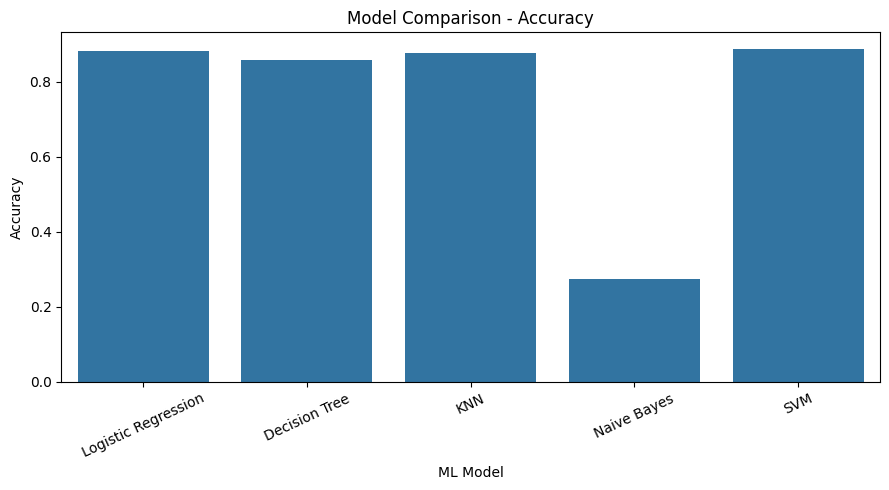

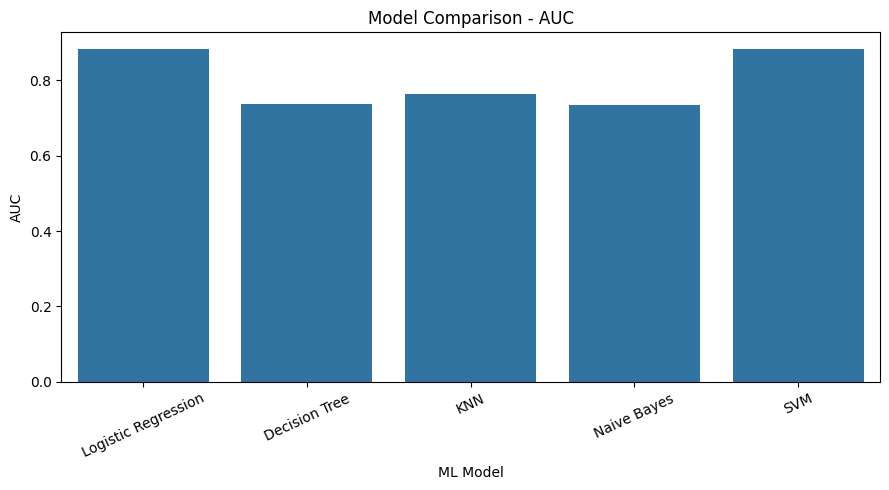

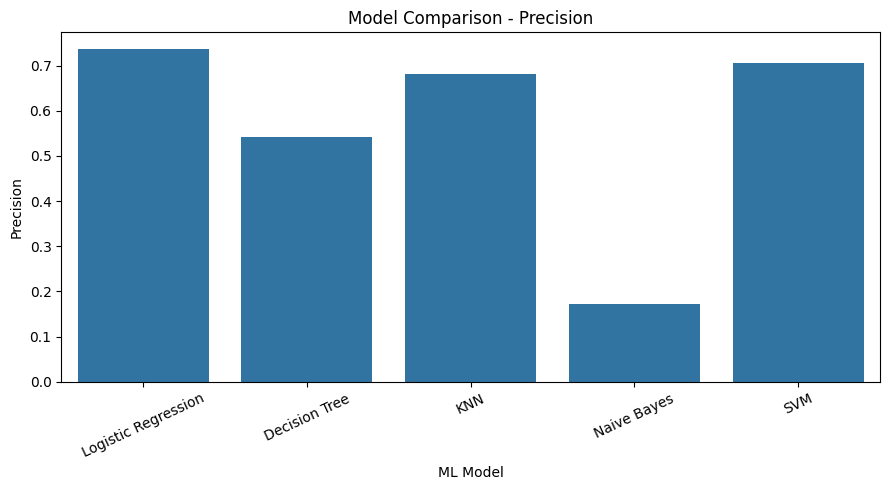

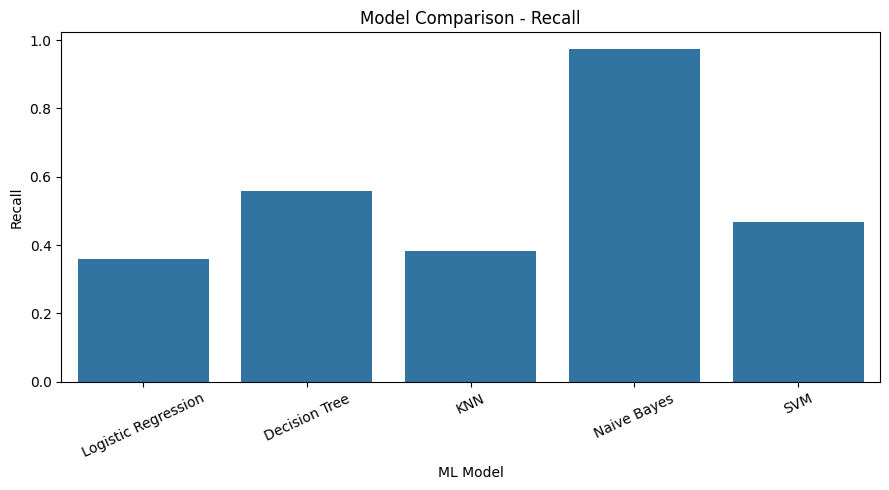

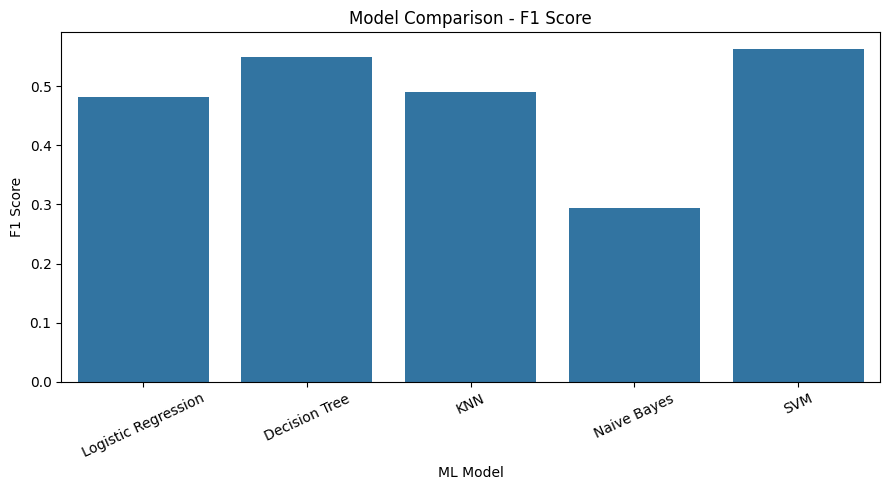

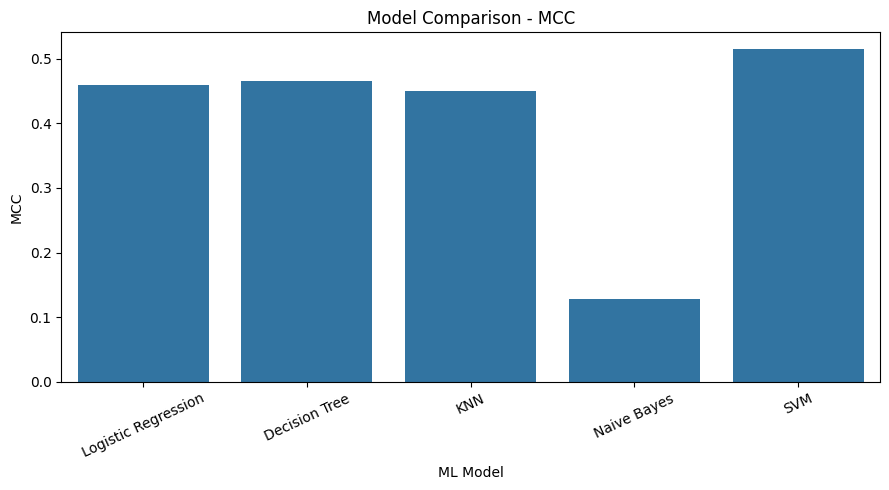

In [36]:
metrics_to_plot = [
    'Accuracy',
    'AUC',
    'Precision',
    'Recall',
    'F1 Score',
    'MCC'
]

for metric in metrics_to_plot:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=results_df.index,
        y=results_df[metric]
    )

    plt.title(f'Model Comparison - {metric}')
    plt.xlabel('ML Model')
    plt.ylabel(metric)

    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

**Observation:**

While Logistic Regression and SVM achieve high precision (>70%), Naive Bayes shows a near-perfect Recall of 97.38% but fails on all other metrics due to extremely high false positive rates.

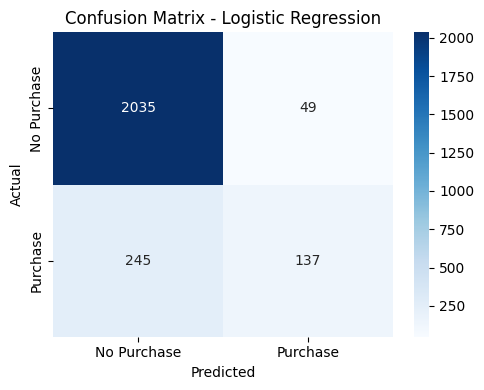

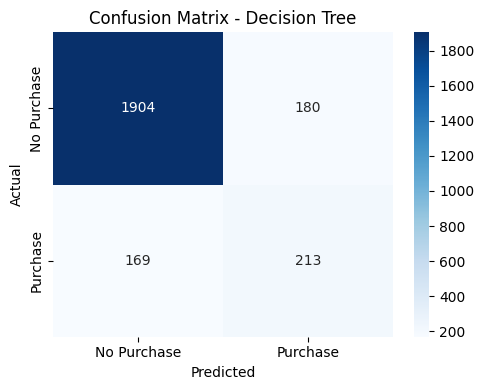

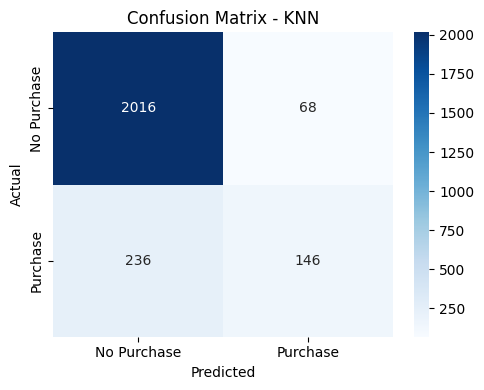

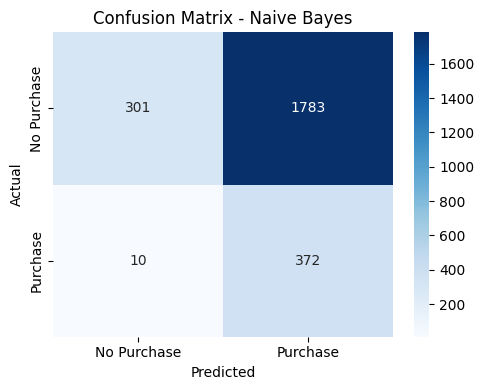

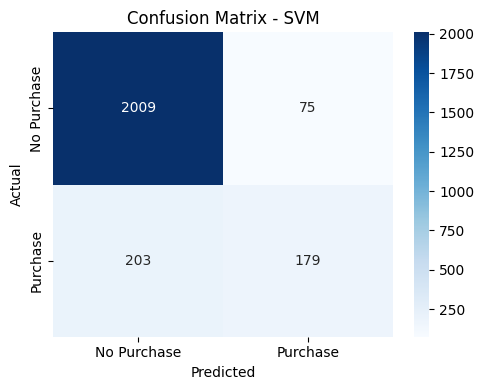

In [37]:
for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[False, True]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Purchase', 'Purchase'],
        yticklabels=['No Purchase', 'Purchase']
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.tight_layout()
    plt.show()

**Observation:**

The confusion matrices show that SVM maintains a solid balance with low false positives (75), whereas Naive Bayes misclassifies 1,783 non-purchasing sessions as purchases (extreme False Positives) to maximize recall.


# 9. Model-wise Analysis

In [38]:
for model_name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(f"Classification Report: {model_name}")
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['No Purchase', 'Purchase'],
            zero_division=0
        )
    )


Classification Report: Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.89      0.98      0.93      2084
    Purchase       0.74      0.36      0.48       382

    accuracy                           0.88      2466
   macro avg       0.81      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466


Classification Report: Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.92      0.91      0.92      2084
    Purchase       0.54      0.56      0.55       382

    accuracy                           0.86      2466
   macro avg       0.73      0.74      0.73      2466
weighted avg       0.86      0.86      0.86      2466


Classification Report: KNN
              precision    recall  f1-score   support

 No Purchase       0.90      0.97      0.93      2084
    Purchase       0.68      0.38      0.49       382

    accuracy                           0.88      2466
   macro avg      

**Observation:**

While Logistic Regression, KNN, and SVM maintain high precision for predicting purchases (>70%), they suffer from low recall (<47%); the Decision Tree yields the most balanced class-specific F1-score (0.55) for the positive class.

In [39]:
for model_name, y_pred in predictions.items():

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[False, True]
    )

    print("TN:", cm[0, 0])
    print("FP:", cm[0, 1])
    print("FN:", cm[1, 0])
    print("TP:", cm[1, 1])


Logistic Regression
TN: 2035
FP: 49
FN: 245
TP: 137

Decision Tree
TN: 1904
FP: 180
FN: 169
TP: 213

KNN
TN: 2016
FP: 68
FN: 236
TP: 146

Naive Bayes
TN: 301
FP: 1783
FN: 10
TP: 372

SVM
TN: 2009
FP: 75
FN: 203
TP: 179


**Observation:**

The raw metrics confirm that while Logistic Regression, KNN, and SVM maintain exceptionally low False Positives (<75), Naive Bayes predicts nearly all positive cases correctly (372 TPs) at the expense of an extremely high False Positive count (1,783).

# 10. Test Dataset Export

In [40]:
# Reconstruct test dataset with original features and target

test_data = X_test.copy()

test_data['Revenue'] = y_test.values

# Save labelled test dataset
test_data.to_csv(
    'test_data.csv',
    index=False
)

print("Test dataset saved successfully!")

print("Shape:", test_data.shape)

print("\nFirst five rows:")
display(test_data.head())

Test dataset saved successfully!
Shape: (2466, 18)

First five rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
4722,1,4.0,0,0.0,13,161.166667,0.024615,0.061538,0.000000,0.6,May,2,5,9,5,Returning_Visitor,False,False
6835,1,23.2,0,0.0,23,290.000000,0.000000,0.033333,0.000000,0.0,Jul,2,2,8,3,Returning_Visitor,False,False
5524,0,0.0,0,0.0,6,95.000000,0.028571,0.028571,86.336233,0.0,Oct,1,1,4,2,New_Visitor,False,True
663,0,0.0,0,0.0,2,17.000000,0.000000,0.100000,0.000000,0.0,Mar,1,1,8,3,Returning_Visitor,False,False
136,0,0.0,0,0.0,9,303.666667,0.005556,0.046296,0.000000,0.0,Feb,2,4,5,2,Returning_Visitor,False,False


In [41]:
# Check target distribution
print("\nRevenue distribution:")
print(test_data['Revenue'].value_counts())

# Check missing values
print("\nMissing values:")
print(test_data.isnull().sum().sum())

# Verify target column exists
print("\nTarget column exists:", 'Revenue' in test_data.columns)


Revenue distribution:
Revenue
False    2084
True      382
Name: count, dtype: int64

Missing values:
0

Target column exists: True


In [42]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

st.set_page_config(
    page_title="Online Shoppers Purchase Prediction",
    page_icon="🛒",
    layout="wide"
)

st.title("Online Shoppers Purchase Intention")
st.write("Evaluate five machine learning models using uploaded test data.")

model_options = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

selected_model = st.selectbox(
    "Select a Classification Model",
    list(model_options.keys())
)

uploaded_file = st.file_uploader(
    "Upload Test Dataset (CSV)",
    type=["csv"]
)

if uploaded_file is not None:

    test_data = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Dataset")
    st.write("Dataset shape:", test_data.shape)
    st.dataframe(test_data.head())

    target_column = "Revenue"

    if target_column not in test_data.columns:
        st.error("The uploaded CSV must contain the Revenue target column.")

    else:
        X_test_app = test_data.drop(columns=[target_column])
        y_test_app = test_data[target_column]

        expected_features = [
            'Administrative', 'Administrative_Duration',
            'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues',
            'SpecialDay', 'Month', 'OperatingSystems',
            'Browser', 'Region', 'TrafficType',
            'VisitorType', 'Weekend'
        ]

        if set(X_test_app.columns) != set(expected_features):
            st.error("Uploaded CSV does not contain the expected 17 features.")

        elif X_test_app.isnull().any().any() or y_test_app.isnull().any():
            st.error("Uploaded CSV contains missing values.")

        elif y_test_app.nunique() != 2:
            st.error("Revenue must contain both target classes.")

        else:
            # Arrange features in the expected order
            X_test_app = X_test_app[expected_features]

            model_path = os.path.join(
                "model", model_options[selected_model]
            )

            if not os.path.exists(model_path):
                st.error(f"Model file not found: {model_path}")

            else:
                model = joblib.load(model_path)

                y_pred = model.predict(X_test_app)
                y_prob = model.predict_proba(X_test_app)[:, 1]

                metrics = {
                    "Accuracy": accuracy_score(y_test_app, y_pred),
                    "AUC": roc_auc_score(y_test_app, y_prob),
                    "Precision": precision_score(
                        y_test_app, y_pred, pos_label=True,
                        zero_division=0
                    ),
                    "Recall": recall_score(
                        y_test_app, y_pred, pos_label=True,
                        zero_division=0
                    ),
                    "F1 Score": f1_score(
                        y_test_app, y_pred, pos_label=True,
                        zero_division=0
                    ),
                    "MCC": matthews_corrcoef(y_test_app, y_pred)
                }

                st.subheader("Model Evaluation Results")
                st.write("Selected Model:", selected_model)

                cols = st.columns(3)
                for col, (name, value) in zip(cols, list(metrics.items())[:3]):
                    col.metric(name, f"{value:.4f}")

                cols = st.columns(3)
                for col, (name, value) in zip(cols, list(metrics.items())[3:]):
                    col.metric(name, f"{value:.4f}")

                st.subheader("Confusion Matrix")

                cm = confusion_matrix(
                    y_test_app, y_pred, labels=[False, True]
                )

                fig, ax = plt.subplots(figsize=(5, 4))
                sns.heatmap(
                    cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=["No Purchase", "Purchase"],
                    yticklabels=["No Purchase", "Purchase"],
                    ax=ax
                )

                ax.set_xlabel("Predicted Label")
                ax.set_ylabel("Actual Label")
                st.pyplot(fig)
                plt.close(fig)

                st.subheader("Classification Report")

                report = classification_report(
                    y_test_app, y_pred,
                    labels=[False, True],
                    target_names=["No Purchase", "Purchase"],
                    output_dict=True,
                    zero_division=0
                )

                st.dataframe(
                    pd.DataFrame(report).transpose().round(4)
                )

else:
    st.info("Please upload a test CSV file to evaluate a model.")

Writing app.py


In [43]:
%%writefile requirements.txt
streamlit==1.66.1
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
joblib==1.6.0
matplotlib==3.10.0
seaborn==0.13.2

Writing requirements.txt


In [44]:
print(os.listdir())

['.config', 'app.py', 'online_shoppers_intention.csv', 'requirements.txt', 'test_data.csv', 'model', 'sample_data']
